[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_15/MFM_ch15_news_signal/MFM_ch15_news_signal.ipynb)

# MFM_ch15_news_signal

From headline sentiment to a trading signal: same-day versus next-day regressions with standard errors clustered by day, an event study around news days, and a daily long-short strategy with and without transaction costs, for Loughran-McDonald, FinBERT and Qwen2.5-7B scores.

The regression table expresses slopes in percentage points per one standard deviation of sentiment; the plot converts them to basis points (100 bp = 1 percentage point). The strategy table reports daily means and intervals in bp, annualised Sharpe ratios before and after costs, and the break-even cost in bp per traded leg. The mean-return intervals are 95% moving-block bootstrap intervals (10-day blocks). A negative break-even value means the gross strategy already loses money at zero cost; it is not a feasible positive cost allowance. Regression r0/r1/r2 refer to the headline day, the next trading day and the following trading day. The event-study confidence bands are pointwise plus/minus 1.96 standard errors. The event-study shading marks trading days +2 to +5; cumulative returns are additive sums, not compounded wealth.

*Modelling Financial Markets (MFM), Chapter 15: LLMs and Sentiment Analysis. Author: Daniel Traian Pele.*

In [1]:
import os
import io
import re
import sys
import json
import time
import zipfile
import subprocess
import urllib.request
for pkg, mod in (('pysentiment2', 'pysentiment2'), ('transformers', 'transformers')):
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

## Data, methods and tests

In [2]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')

PHRASEBANK_URL = ('https://huggingface.co/datasets/takala/financial_phrasebank/resolve/main/data/'
                  'FinancialPhraseBank-v1.0.zip')
TWITTER_URL = 'https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment/resolve/main/'
FNSPID_URLS = ['https://huggingface.co/datasets/Zihan1004/FNSPID/resolve/main/Stock_news/All_external.csv',
               'https://huggingface.co/datasets/Zihan1004/FNSPID/resolve/main/Stock_news/nasdaq_exteral_data.csv']
LABELS = ['negative', 'neutral', 'positive']
TW_MAP = {0: 'negative', 1: 'positive', 2: 'neutral'}          # Bearish, Bullish, Neutral
AGREE = ['50Agree', '66Agree', '75Agree', 'AllAgree']

# US stocks with FNSPID news and daily prices in the course data (Meta appears in FNSPID as FB until 2022)
TICKERS = {'AAPL': 'AAPL.US', 'MSFT': 'MSFT.US', 'AMZN': 'AMZN.US', 'NVDA': 'NVDA.US', 'TSLA': 'TSLA.US',
           'GOOGL': 'GOOGL.US', 'GOOG': 'GOOGL.US', 'META': 'META.US', 'FB': 'META.US', 'JPM': 'JPM.US',
           'BAC': 'BAC.US', 'C': 'C.US', 'GS': 'GS.US', 'MS': 'MS.US', 'WFC': 'WFC.US', 'CSCO': 'CSCO.US',
           'GME': 'GME.US', 'MSTR': 'MSTR.US', 'COIN': 'COIN.US'}
LLM_SIZES = {'0.5B': 'Qwen/Qwen2.5-0.5B-Instruct', '1.5B': 'Qwen/Qwen2.5-1.5B-Instruct',
             '3B': 'Qwen/Qwen2.5-3B-Instruct', '7B': 'Qwen/Qwen2.5-7B-Instruct', '14B': 'Qwen/Qwen2.5-14B-Instruct'}
QWEN_RELEASE = '2024-09-19'          # release of the Qwen2.5 weights
PROMPTS = {
    'P1': ('You classify the sentiment of financial news for investors. '
           'Answer with one word: positive, negative or neutral.', 'Headline: {x}\nSentiment:'),
    'P2': ('You are a financial analyst.', 'Is the following news good, bad or neutral for the stock price of the '
                                           'company it mentions? Answer with one word: positive, negative or '
                                           'neutral.\n\n{x}'),
    'P3': ('You are a helpful assistant.', 'Text: "{x}"\nWhat is the sentiment of this text? Reply positive, '
                                           'negative or neutral.'),
}


# =============================================================================
# MARKET DATA
# =============================================================================
def read_market(symbol):
    """Daily prices of one asset from the course data (local copy or the GitHub repository)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def stock_returns(symbols, start='2009-01-01'):
    """Simple daily close-to-close returns (%) on the adjusted price, for the stocks and SPY.
    Prices are joined on common days, then returns are computed."""
    px = pd.concat({s: read_market(s)['adjusted_close'] for s in symbols}, axis=1).loc[start:]
    return 100 * px.pct_change(fill_method=None)


# =============================================================================
# LABELLED TEXTS
# =============================================================================
def load_phrasebank():
    """Financial PhraseBank v1.0: 4,846 sentences from financial news, labelled by 16 annotators.
    'agree': the highest agreement threshold reached (50%, 66%, 75%, 100%)."""
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(PHRASEBANK_URL).read()))
    sets = {}
    for lvl in AGREE:
        raw = z.read(f'FinancialPhraseBank-v1.0/Sentences_{lvl}.txt').decode('latin-1')
        sets[lvl] = [tuple(l.rsplit('@', 1)) for l in raw.splitlines() if '@' in l]
    lookup = {lvl: set(v) for lvl, v in sets.items()}
    rows = []
    for text, lab in sets['50Agree']:
        agree = max([i for i, lvl in enumerate(AGREE) if (text, lab) in lookup[lvl]] or [0])
        rows.append((text.strip(), lab.strip(), AGREE[agree]))
    d = pd.DataFrame(rows, columns=['text', 'label', 'agree'])
    return d


def load_twitter(split='valid'):
    """Twitter Financial News Sentiment: financial news headlines posted on Twitter, 2022; train / valid."""
    d = pd.read_csv(TWITTER_URL + f'sent_{split}.csv')
    d['label'] = d['label'].map(TW_MAP)
    return d


# =============================================================================
# DICTIONARIES
# =============================================================================
def load_dictionaries():
    """Word lists: Loughran-McDonald (negative, positive, uncertainty) and Harvard IV-4 (Negativ, Positiv).
    Source: the lists distributed with the pysentiment2 package."""
    try:
        import pysentiment2
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pysentiment2'], check=True)
        import pysentiment2
    st = os.path.join(os.path.dirname(pysentiment2.__file__), 'static')
    lm = pd.read_csv(os.path.join(st, 'LM.csv'))
    lm['Word'] = lm['Word'].astype(str).str.upper()
    gi = pd.read_csv(os.path.join(st, 'HIV-4.csv'), dtype=str)
    gi['Entry'] = gi['Entry'].astype(str).str.upper().str.replace(r'#\d+$', '', regex=True)
    return {'LM_neg': set(lm.loc[lm['Negative'] > 0, 'Word']),
            'LM_pos': set(lm.loc[lm['Positive'] > 0, 'Word']),
            'LM_unc': set(lm.loc[lm['Uncertainty'] > 0, 'Word']),
            'GI_neg': set(gi.loc[gi['Negativ'].notna(), 'Entry']),
            'GI_pos': set(gi.loc[gi['Positiv'].notna(), 'Entry'])}


TOKEN = re.compile(r"[A-Za-z][A-Za-z'\-]*")


def tokens(text):
    """Upper-case words, without digits and punctuation."""
    return [w.upper().strip("'-") for w in TOKEN.findall(str(text))]


def dict_counts(texts, pos, neg):
    """Number of positive and negative words in each text."""
    P = np.array([sum(w in pos for w in tokens(t)) for t in texts])
    N = np.array([sum(w in neg for w in tokens(t)) for t in texts])
    return P, N


def dict_tone(texts, pos, neg):
    """Tone: (P - N) / (P + N); 0 if the text has no dictionary words."""
    P, N = dict_counts(texts, pos, neg)
    return np.where(P + N > 0, (P - N) / np.maximum(P + N, 1), 0.0)


def tone_label(tone, band=0.0):
    return np.where(tone > band, 'positive', np.where(tone < -band, 'negative', 'neutral'))


def vader_compound(texts):
    """VADER compound score (Hutto & Gilbert, 2014), in [-1, 1]."""
    import nltk
    try:
        from nltk.sentiment.vader import SentimentIntensityAnalyzer
        sia = SentimentIntensityAnalyzer()
    except LookupError:
        nltk.download('vader_lexicon', quiet=True)
        from nltk.sentiment.vader import SentimentIntensityAnalyzer
        sia = SentimentIntensityAnalyzer()
    return np.array([sia.polarity_scores(str(t))['compound'] for t in texts])


# =============================================================================
# LANGUAGE MODELS
# =============================================================================
def device():
    import torch
    if torch.cuda.is_available():
        return 'cuda'
    if torch.backends.mps.is_available():
        return 'mps'
    return 'cpu'


def finbert_probs(texts, batch=64, name='ProsusAI/finbert'):
    """FinBERT probabilities (negative, neutral, positive) for each text."""
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok = AutoTokenizer.from_pretrained(name)
    m = AutoModelForSequenceClassification.from_pretrained(name).to(device()).eval()
    order = [m.config.label2id[l] for l in LABELS]
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch):
            b = tok([str(t) for t in texts[i:i + batch]], padding=True, truncation=True, max_length=96,
                    return_tensors='pt').to(m.device)
            out.append(m(**b).logits.float().softmax(-1)[:, order].cpu().numpy())
    return np.vstack(out)


def llm_load(size):
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    name = LLM_SIZES[size]
    tok = AutoTokenizer.from_pretrained(name)
    tok.padding_side = 'left'
    dev = device()
    dt = torch.float16 if dev != 'cpu' else torch.float32
    m = AutoModelForCausalLM.from_pretrained(name, dtype=dt).to(dev).eval()
    return tok, m


def llm_choice_probs(tok, m, system, user_texts, choices, batch=16):
    """Zero-shot: relative probabilities of the answer words (first token of each) at the first generation
    step, after the model's chat template."""
    import torch
    ids = [tok.encode(w, add_special_tokens=False)[0] for w in choices]
    prompts = [tok.apply_chat_template([{'role': 'system', 'content': system}, {'role': 'user', 'content': u}],
                                       tokenize=False, add_generation_prompt=True) for u in user_texts]
    out = []
    with torch.no_grad():
        for i in range(0, len(prompts), batch):
            b = tok(prompts[i:i + batch], return_tensors='pt', padding=True).to(m.device)
            lg = m(**b).logits[:, -1, :][:, ids].float()
            out.append(lg.softmax(-1).cpu().numpy())
    return np.vstack(out)


def llm_sentiment(tok, m, texts, prompt='P1', batch=16):
    """Probabilities (negative, neutral, positive) from a zero-shot LLM."""
    system, user = PROMPTS[prompt]
    return llm_choice_probs(tok, m, system, [user.format(x=str(t)) for t in texts], LABELS, batch)


def embed(texts, name='sentence-transformers/all-MiniLM-L6-v2', batch=128):
    """Sentence embeddings: mean of the hidden states (mean pooling), normalised to unit length."""
    import torch
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(name)
    m = AutoModel.from_pretrained(name).to(device()).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch):
            b = tok([str(t) for t in texts[i:i + batch]], padding=True, truncation=True, max_length=96,
                    return_tensors='pt').to(m.device)
            h = m(**b).last_hidden_state
            w = b['attention_mask'].unsqueeze(-1).float()
            e = (h * w).sum(1) / w.sum(1)
            out.append(torch.nn.functional.normalize(e, dim=1).cpu().numpy())
    return np.vstack(out)


def probs_label(P):
    """Label with the highest probability; columns are in the order of LABELS."""
    return np.array(LABELS)[np.asarray(P).argmax(1)]


def net_score(P):
    """Net sentiment score: P(positive) - P(negative), in [-1, 1]."""
    P = np.asarray(P)
    return P[:, 2] - P[:, 0]


# =============================================================================
# CLASSIFICATION METRICS
# =============================================================================
def confusion(y, yhat, labels=LABELS):
    return pd.crosstab(pd.Categorical(y, labels), pd.Categorical(yhat, labels), dropna=False,
                       rownames=['true'], colnames=['predicted'])


def macro_f1(y, yhat, labels=LABELS):
    y, yhat = np.asarray(y), np.asarray(yhat)
    f = []
    for l in labels:
        tp = np.sum((y == l) & (yhat == l))
        p = tp / max(np.sum(yhat == l), 1)
        r = tp / max(np.sum(y == l), 1)
        f.append(0 if p + r == 0 else 2 * p * r / (p + r))
    return float(np.mean(f))


def class_metrics(y, yhat, labels=LABELS):
    """Precision, recall and F1 by class."""
    y, yhat = np.asarray(y), np.asarray(yhat)
    rows = {}
    for l in labels:
        tp = np.sum((y == l) & (yhat == l))
        p = tp / max(np.sum(yhat == l), 1)
        r = tp / max(np.sum(y == l), 1)
        rows[l] = {'precision': p, 'recall': r, 'f1': 0 if p + r == 0 else 2 * p * r / (p + r),
                   'support': int(np.sum(y == l))}
    return pd.DataFrame(rows).T


def boot_ci(y, yhat, stat, B=2000, seed=0, level=0.95):
    """Bootstrap interval (i.i.d. resampling of texts) for a classification statistic."""
    rng = np.random.default_rng(seed)
    y, yhat = np.asarray(y), np.asarray(yhat)
    n = len(y)
    v = [stat(y[i], yhat[i]) for i in (rng.integers(0, n, n) for _ in range(B))]
    return tuple(np.quantile(v, [(1 - level) / 2, (1 + level) / 2]))


def acc(y, yhat):
    return float(np.mean(np.asarray(y) == np.asarray(yhat)))


def mcnemar(y, a, b):
    """Exact McNemar test: compares two classifiers on the same texts.
    n01: A wrong and B right; n10: the reverse."""
    y, a, b = map(np.asarray, (y, a, b))
    ca, cb = a == y, b == y
    n01, n10 = int(np.sum(~ca & cb)), int(np.sum(ca & ~cb))
    p = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 > 0 else 1.0
    return n01, n10, float(p)


def diff_ci(y, a, b, B=2000, seed=0):
    """Bootstrap interval for the accuracy difference acc(B) - acc(A), on the same texts."""
    rng = np.random.default_rng(seed)
    y, a, b = map(np.asarray, (y, a, b))
    n = len(y)
    d = [np.mean(b[i] == y[i]) - np.mean(a[i] == y[i]) for i in (rng.integers(0, n, n) for _ in range(B))]
    return tuple(np.quantile(d, [0.025, 0.975]))


# =============================================================================
# DATED NEWS AND SIGNALS
# =============================================================================
def load_fnspid(paths=None, tickers=TICKERS):
    """FNSPID headlines (both parts: external sources and Nasdaq) for the stocks in TICKERS:
    date (UTC), headline, ticker. Repeated headlines (same headline, stock and day) are kept once."""
    out = []
    for src in (paths or FNSPID_URLS):
        for ch in pd.read_csv(src, usecols=['Date', 'Article_title', 'Stock_symbol'], chunksize=500_000, dtype=str,
                              on_bad_lines='skip'):
            out.append(ch[ch['Stock_symbol'].isin(tickers)])
    d = pd.concat(out).dropna()
    d['ts'] = pd.to_datetime(d['Date'], utc=True, errors='coerce')
    d = d.dropna(subset=['ts'])
    d['ticker'] = d['Stock_symbol'].map(lambda s: TICKERS[s].replace('.US', ''))
    d['title'] = d['Article_title'].str.strip()
    d = d.assign(dd=d['ts'].dt.date).drop_duplicates(['ticker', 'title', 'dd'])
    return d[['ts', 'ticker', 'title']].reset_index(drop=True)


def assign_trading_day(ts, days):
    """FNSPID gives only the publication date (the time is 00:00 UTC for almost all headlines): a headline dated d
    is assigned to the first trading day >= d. The time of day is unknown, so the news may appear
    after the close of day d."""
    d0 = ts.dt.tz_convert('UTC').dt.tz_localize(None).dt.normalize()
    days = pd.DatetimeIndex(days).sort_values()
    pos = days.searchsorted(d0.values)
    ok = pos < len(days)
    out = pd.Series(pd.NaT, index=ts.index)
    out[ok] = days[pos[ok]]
    return out


def daily_panel(S, rets):
    """S: mean scores by (day, stock), indexed (day, ticker). Adds the excess return over SPY
    on the news day (r0), on the next two days (r1, r2) and on days -5..+5 (event study:
    rm5..rm1, r0, r1, r2, rp3..rp5). Without a time stamp, r1 may still contain the reaction to the news; the first
    safely tradable return is r2 (from the close of the next day)."""
    ex = rets.drop(columns='SPY').sub(rets['SPY'], axis=0)
    P = S.copy()
    for k in range(-5, 6):
        name = {0: 'r0', 1: 'r1', 2: 'r2'}.get(k, f'rp{k}' if k > 0 else f'rm{-k}')
        sh = ex.shift(-k).stack()
        sh.index.names = ['day', 'ticker']
        P = P.join(sh.rename(name), how='left')
    return P.dropna(subset=['r0', 'r1', 'r2'])


def cluster_ols(y, x, groups):
    """OLS y = a + b x with ordinary and day-clustered standard errors (Petersen, 2009)."""
    X = np.column_stack([np.ones(len(x)), x])
    y = np.asarray(y, float)
    XtX = np.linalg.inv(X.T @ X)
    b = XtX @ X.T @ y
    e = y - X @ b
    n, k = X.shape
    V_ols = XtX * (e @ e) / (n - k)
    idx_g = pd.Series(np.arange(n)).groupby(np.asarray(groups)).apply(list)
    meat = sum(np.outer(X[i].T @ e[i], X[i].T @ e[i]) for i in idx_g)
    G = len(idx_g)
    V_cl = XtX @ meat @ XtX * G / (G - 1) * (n - 1) / (n - k)
    return {'b': b[1], 'a': b[0], 'se_ols': np.sqrt(V_ols[1, 1]), 'se_cl': np.sqrt(V_cl[1, 1]),
            't_ols': b[1] / np.sqrt(V_ols[1, 1]), 't_cl': b[1] / np.sqrt(V_cl[1, 1]),
            'r2': 1 - (e @ e) / np.sum((y - y.mean()) ** 2), 'n': n, 'G': G}


def nw_t(x, lags=None):
    """Mean and t statistic with the Newey-West (HAC) variance."""
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    n = len(x)
    L = lags if lags is not None else int(np.floor(4 * (n / 100) ** (2 / 9)))
    u = x - x.mean()
    v = u @ u / n
    for l in range(1, L + 1):
        v += 2 * (1 - l / (L + 1)) * (u[l:] @ u[:-l]) / n
    return x.mean(), x.mean() / np.sqrt(v / n)


def block_boot_mean(x, B=2000, block=10, seed=0):
    """Moving-block bootstrap interval for the mean of a daily series."""
    rng = np.random.default_rng(seed)
    x = np.asarray(x, float)
    n = len(x)
    nb = int(np.ceil(n / block))
    v = []
    for _ in range(B):
        st = rng.integers(0, n - block + 1, nb)
        v.append(np.concatenate([x[s:s + block] for s in st])[:n].mean())
    return tuple(np.quantile(v, [0.025, 0.975]))


def signal_portfolio(P, col, days, cost_bp=0.0, band=0.0, ret='r2'):
    """Daily strategy: for each stock with news (|score| > band) take the position sign(score), hedged with SPY,
    equal weights; the gain is the excess return in column ret (default r2: the position opens at the
    close of the day after the news, when the news is surely public). Days without positions return 0.
    Cost: cost_bp basis points per trade (stock and SPY, at entry and at exit: 4 x cost)."""
    q = P[P[col].abs() > band]
    lag = {'r0': 0, 'r1': 1, 'r2': 2}[ret]
    pos_day = pd.DatetimeIndex(days)
    idx = pos_day.get_indexer(q.index.get_level_values('day'))
    ok = (idx >= 0) & (idx + lag < len(pos_day))
    q = q[ok]
    earn_day = pos_day[idx[ok] + lag]
    x = pd.Series(np.sign(q[col].values) * q[ret].values, index=earn_day)
    grp = x.groupby(level=0)
    R = pd.DataFrame({'gross': grp.mean(), 'k': grp.size()}).reindex(pos_day).fillna(0.0)
    R['net'] = R['gross'] - np.where(R['k'] > 0, 4 * cost_bp / 100, 0.0)
    return R


def sharpe(x, ppy=252):
    x = np.asarray(x, float)
    return float(np.sqrt(ppy) * x.mean() / x.std(ddof=1))

## Style and helpers

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Colours
MainBlue = '#1A3A6E'
IDAred = '#CD0000'
Forest = '#2E7D32'
Amber = '#B5853F'
Orange = '#E67E22'
Purple = '#8E44AD'
Crimson = '#DC3545'
Teal = '#17A2B8'
Magenta = '#D63384'
Brown = '#795548'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts

LAB_COL = {'negative': IDAred, 'neutral': Amber, 'positive': Forest}
METHODS = ['GI', 'VADER', 'LM', 'TF-IDF + LR', 'MiniLM + LR', 'FinBERT', 'Qwen 0.5B', 'Qwen 1.5B', 'Qwen 3B',
           'Qwen 7B', 'Qwen 14B']
M_COL = {'GI': Brown, 'VADER': Amber, 'LM': Orange, 'TF-IDF + LR': Teal, 'MiniLM + LR': Magenta,
         'FinBERT': MainBlue, 'Qwen 0.5B': '#F4A6A6', 'Qwen 1.5B': '#E86A6A', 'Qwen 3B': Crimson,
         'Qwen 7B': IDAred, 'Qwen 14B': '#7A0000'}
SIZES_B = {'0.5B': 0.5, '1.5B': 1.5, '3B': 3.0, '7B': 7.0, '14B': 14.0}
SCORE_LBL = {'lm': 'Loughran-McDonald tone', 'finbert': 'FinBERT', 'qwen': 'Qwen2.5-7B'}
SCORE_COL = {'lm': Orange, 'finbert': MainBlue, 'qwen': IDAred}
EVENT_COLS = ['rm5', 'rm4', 'rm3', 'rm2', 'rm1', 'r0', 'r1', 'r2', 'rp3', 'rp4', 'rp5']
PERIODS = (('2010', '2015'), ('2016', '2019'), ('2020', '2021'), ('2022', '2023'))


RES = {}
FC_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/Quantlets/Ch_15/'
FC_DIR = next((d for d in ('.', '..', 'Quantlets/Ch_15', '../Quantlets/Ch_15', '../../Quantlets/Ch_15')
               if os.path.exists(os.path.join(d, 'ch15_twitter_scores.csv'))), None)


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(os.path.join(globals().get('OUT_DIR', '.'), f'{name}.pdf'), bbox_inches='tight', transparent=True)
    plt.savefig(os.path.join(globals().get('OUT_DIR', '.'), f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def load_csv(name, **kw):
    """A saved score table of the chapter, local copy or the repository."""
    path = os.path.join(FC_DIR, name) if FC_DIR else FC_RAW + name
    return pd.read_csv(path, **kw)


def legend_outside_bottom(ax, ncol=2, y=-0.22, **kw):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False, **kw)


def fig_legend_bottom(fig, handles, labels, ncol=3, y=0.0):
    """One legend for the whole figure, below the panels."""
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def predictions(d):
    """Label predicted by each method (one column per method in the score tables)."""
    v = d['vader'].values
    out = {'GI': tone_label(d['GI_tone'].values), 'LM': tone_label(d['LM_tone'].values),
           'VADER': np.where(v >= 0.05, 'positive', np.where(v <= -0.05, 'negative', 'neutral')),
           'TF-IDF + LR': probs_label(d[[f'tfidf_{l}' for l in LABELS]].values),
           'MiniLM + LR': probs_label(d[[f'emb_{l}' for l in LABELS]].values),
           'FinBERT': probs_label(d[[f'finbert_{l}' for l in LABELS]].values)}
    for s in SIZES_B:
        out[f'Qwen {s}'] = probs_label(d[[f'qwen{s}_{l}' for l in LABELS]].values)
    return out


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items() if not isinstance(v, pd.DataFrame)}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o

LAB_COL = {'negative': '#CD0000', 'neutral': '#B5853F', 'positive': '#2E7D32'}
METHODS = ['GI', 'VADER', 'LM', 'TF-IDF + LR', 'MiniLM + LR', 'FinBERT', 'Qwen 0.5B', 'Qwen 1.5B', 'Qwen 3B', 'Qwen 7B', 'Qwen 14B']
M_COL = {'GI': '#795548', 'VADER': '#B5853F', 'LM': '#E67E22', 'TF-IDF + LR': '#17A2B8', 'MiniLM + LR': '#D63384', 'FinBERT': '#1A3A6E', 'Qwen 0.5B': '#F4A6A6', 'Qwen 1.5B': '#E86A6A', 'Qwen 3B': '#DC3545', 'Qwen 7B': '#CD0000', 'Qwen 14B': '#7A0000'}
SIZES_B = {'0.5B': 0.5, '1.5B': 1.5, '3B': 3.0, '7B': 7.0, '14B': 14.0}
SCORE_LBL = {'lm': 'Loughran-McDonald tone', 'finbert': 'FinBERT', 'qwen': 'Qwen2.5-7B'}
SCORE_COL = {'lm': '#E67E22', 'finbert': '#1A3A6E', 'qwen': '#CD0000'}
EVENT_COLS = ['rm5', 'rm4', 'rm3', 'rm2', 'rm1', 'r0', 'r1', 'r2', 'rp3', 'rp4', 'rp5']
PERIODS = (('2010', '2015'), ('2016', '2019'), ('2020', '2021'), ('2022', '2023'))

## Sentiment scores

In [4]:
HERE = globals().get('OUT_DIR', '.')
SEED = 15
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']


def tick(msg, t0):
    print(f'   {msg}: {time.time() - t0:.0f}s', flush=True)


def dict_cols(d, texts, D):
    for k in ('LM', 'GI'):
        P, N = dict_counts(texts, D[k + '_pos'], D[k + '_neg'])
        d[f'{k}_pos'], d[f'{k}_neg'] = P, N
        d[f'{k}_tone'] = np.where(P + N > 0, (P - N) / np.maximum(P + N, 1), 0.0)
    d['vader'] = vader_compound(texts)


def texts_block():
    t0 = time.time()
    pb, tw, tr = load_phrasebank(), load_twitter('valid'), load_twitter('train')
    D = load_dictionaries()
    out = {'pb': pb[['label', 'agree']].copy(), 'tw': tw[['label']].copy()}
    src = {'pb': pb['text'].tolist(), 'tw': tw['text'].tolist()}
    for k in out:
        dict_cols(out[k], src[k], D)
    tick('dictionaries', t0)
    for k in out:
        P = finbert_probs(src[k])
        for j, l in enumerate(LABELS):
            out[k][f'finbert_{l}'] = P[:, j]
    tick('FinBERT', t0)
    for size in LLM_SIZES:
        tok, m = llm_load(size)
        for k in out:
            prompts = ['P1', 'P2', 'P3'] if (k == 'tw' and size in ('1.5B', '7B', '14B')) else ['P1']
            for pr in prompts:
                t1 = time.time()
                P = llm_sentiment(tok, m, src[k], pr)
                tag = f'qwen{size}' + ('' if pr == 'P1' else f'_{pr}')
                for j, l in enumerate(LABELS):
                    out[k][f'{tag}_{l}'] = P[:, j]
                out[k].attrs[f'time_{tag}'] = (time.time() - t1) / len(src[k])
        del m
        try:
            import torch
            torch.mps.empty_cache()
        except Exception:
            pass
        tick(f'Qwen {size}', t0)
    # embeddings + logistic regression, trained on the Twitter training set
    from sklearn.linear_model import LogisticRegression
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import PCA
    Etr, Etw, Epb = embed(tr['text'].tolist()), embed(src['tw']), embed(src['pb'])
    clf = LogisticRegression(C=4.0, max_iter=3000).fit(Etr, tr['label'])
    for k, E in (('tw', Etw), ('pb', Epb)):
        P = clf.predict_proba(E)[:, [list(clf.classes_).index(l) for l in LABELS]]
        for j, l in enumerate(LABELS):
            out[k][f'emb_{l}'] = P[:, j]
    tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(tr['text'])
    clf2 = LogisticRegression(C=8.0, max_iter=3000).fit(tf.transform(tr['text']), tr['label'])
    for k in out:
        P = clf2.predict_proba(tf.transform(src[k]))[:, [list(clf2.classes_).index(l) for l in LABELS]]
        for j, l in enumerate(LABELS):
            out[k][f'tfidf_{l}'] = P[:, j]
    pc = PCA(2, random_state=SEED).fit(Etr)
    xy = pc.transform(Etw)
    out['tw']['pc1'], out['tw']['pc2'] = xy[:, 0], xy[:, 1]
    tick('embeddings', t0)
    # learning curve: how many labels are needed?
    rng = np.random.default_rng(SEED)
    rows = []
    for n in (100, 200, 400, 800, 1600, 3200, 6400, len(tr)):
        for rep in range(10 if n < len(tr) else 1):
            idx = rng.choice(len(tr), n, replace=False) if n < len(tr) else np.arange(len(tr))
            y = tr['label'].values[idx]
            if len(set(y)) < 3:
                continue
            a = LogisticRegression(C=4.0, max_iter=3000).fit(Etr[idx], y).predict(Etw)
            tfn = TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True).fit(tr['text'].values[idx])
            b = LogisticRegression(C=8.0, max_iter=3000).fit(tfn.transform(tr['text'].values[idx]), y).predict(
                tfn.transform(src['tw']))
            rows.append({'n': n, 'rep': rep, 'emb_acc': acc(tw['label'], a), 'emb_f1': macro_f1(tw['label'], a),
                         'tfidf_acc': acc(tw['label'], b), 'tfidf_f1': macro_f1(tw['label'], b)})
    pd.DataFrame(rows).to_csv(os.path.join(HERE, 'ch15_learning_curve.csv'), index=False)
    for k, name in (('pb', 'ch15_phrasebank_scores.csv'), ('tw', 'ch15_twitter_scores.csv')):
        # full precision: rounding to 6 decimals turns small class probabilities into exact zeros, which the
        # temperature scaling of valid_inference.py can then only replace by a numerical floor
        out[k].to_csv(os.path.join(HERE, name), index_label='id', float_format='%.17g')
    times = {**out['tw'].attrs}
    pd.Series(times).to_csv(os.path.join(HERE, 'ch15_llm_time.csv'), header=['sec_per_text'])
    tick('texts done', t0)


def memory_block(sizes=('1.5B', '7B', '14B')):
    """Monthly direction of the S&P 500 (2000-2026) and daily direction of Apple, asked with no context."""
    t0 = time.time()
    px = read_market('GSPC.INDX')['close']
    mon = px.resample('ME').last()
    mret = 100 * mon.pct_change().dropna().loc['2000-01':'2026-08']
    aapl = read_market('AAPL.US')['adjusted_close']
    dret = 100 * aapl.pct_change().dropna()
    rng = np.random.default_rng(SEED)
    pre = dret.loc['2010-01-01':'2023-12-31']
    post = dret.loc['2024-10-01':]
    days = pd.concat([pre.iloc[np.sort(rng.choice(len(pre), 500, replace=False))], post])
    dm = pd.DataFrame({'ret': mret})
    dd = pd.DataFrame({'ret': days})
    sys_m = 'You are a financial historian. Answer with one word: rise or fall.'
    q_m = [f'Did the S&P 500 index rise or fall during {MONTHS[d.month - 1]} {d.year}?' for d in dm.index]
    sys_d = 'You are a financial historian. Answer with one word: higher or lower.'
    q_d = [f'Did Apple (AAPL) stock close higher or lower on {d.strftime("%A")}, {MONTHS[d.month - 1]} {d.day}, '
           f'{d.year} than on the previous trading day?' for d in dd.index]
    for size in sizes:
        tok, m = llm_load(size)
        dm[f'qwen{size}'] = llm_choice_probs(tok, m, sys_m, q_m, ['rise', 'fall'])[:, 0]
        dd[f'qwen{size}'] = llm_choice_probs(tok, m, sys_d, q_d, ['higher', 'lower'])[:, 0]
        del m
        tick(f'memory {size}', t0)
    dm.round(6).to_csv(os.path.join(HERE, 'ch15_memory_monthly.csv'), index_label='month')
    dd.round(6).to_csv(os.path.join(HERE, 'ch15_memory_daily.csv'), index_label='date')


def news_block(paths=None, llm='7B', batch=64):
    """Scores for each headline, then means by (trading day, stock)."""
    t0 = time.time()
    news = load_fnspid(paths)
    tick(f'FNSPID {len(news)} headlines', t0)
    rets = stock_returns(sorted(set(TICKERS.values())) + ['SPY.US'], start='2009-01-01')
    rets.columns = [c.replace('.US', '') for c in rets.columns]
    news['day'] = assign_trading_day(news['ts'], rets.index)
    news = news.dropna(subset=['day'])
    news = news[news['day'] >= '2009-06-01']
    D = load_dictionaries()
    P, N = dict_counts(news['title'].tolist(), D['LM_pos'], D['LM_neg'])
    news['lm'] = np.where(P + N > 0, (P - N) / np.maximum(P + N, 1), 0.0)
    news['lm_hit'] = (P + N > 0).astype(int)
    F = finbert_probs(news['title'].tolist(), batch=256)
    news['finbert'] = net_score(F)
    news['finbert_lab'] = F.argmax(1) - 1
    tick('FinBERT', t0)
    tok, m = llm_load(llm)
    Q = llm_sentiment(tok, m, news['title'].tolist(), 'P1', batch=batch)
    news['qwen'] = net_score(Q)
    tick(f'Qwen {llm}', t0)
    grp = news.groupby(['day', 'ticker'])
    daily = grp[['finbert', 'lm', 'qwen']].mean()
    daily['n'] = grp.size()
    daily['lm_hit'] = grp['lm_hit'].mean()
    daily.round(6).to_csv(os.path.join(HERE, 'ch15_news_daily.csv'))
    by_year = news.groupby([news['day'].dt.year, 'ticker']).size().unstack(fill_value=0)
    by_year.to_csv(os.path.join(HERE, 'ch15_news_counts.csv'))
    hour = news['ts'].dt.tz_convert('UTC').dt.hour.value_counts().reindex(range(24), fill_value=0)
    exact = ((news['ts'].dt.hour == 0) & (news['ts'].dt.minute == 0) & (news['ts'].dt.second == 0)).mean()
    pd.DataFrame({'n': hour, 'share_midnight': exact}).to_csv(os.path.join(HERE, 'ch15_news_hours.csv'))
    # scores of the individual headlines (without text) for the comparison of methods
    news[['day', 'ticker', 'finbert', 'finbert_lab', 'lm', 'lm_hit', 'qwen']].round(5).to_csv(
        os.path.join(HERE, 'ch15_news_headlines.csv.gz'), index=False, compression='gzip')
    tick('news done', t0)

In [5]:
# True: recompute all scores (downloads FinBERT, MiniLM, Qwen2.5 0.5B-14B and the FNSPID
# headlines; hours without a GPU); False: use the scores saved with Chapter 15.
RECOMPUTE = False
if RECOMPUTE:
    texts_block()
    memory_block()
    news_block()
    FC_DIR = HERE

## Analysis

In [6]:
def news_panel():
    daily = load_csv('ch15_news_daily.csv', parse_dates=['day']).set_index(['day', 'ticker'])
    syms = sorted(set(TICKERS.values()))
    rets = stock_returns(syms + ['SPY.US'], start='2009-01-01')
    rets.columns = [c.replace('.US', '') for c in rets.columns]
    rets = rets.loc[:'2023-12-31']
    P = daily_panel(daily, rets)
    for c in SCORE_LBL:
        P[f'z_{c}'] = (P[c] - P[c].mean()) / P[c].std()
    return P, rets


def event_groups(x):
    """Event-study groups: the most negative and the most positive tercile of the daily score. If the two
    cut-offs coincide (the LM tone is exactly 0 on almost half of the stock-days), the disjoint groups are
    score < cut-off and score > cut-off, and days equal to the cut-off are excluded."""
    q1, q2 = x.quantile([1 / 3, 2 / 3])
    if q1 >= q2:
        return x < q1, x > q2
    return x <= q1, x >= q2


def eval_news(P, rets):
    cnt = load_csv('ch15_news_counts.csv', index_col=0)
    hl = load_csv('ch15_news_headlines.csv.gz', usecols=['finbert', 'lm', 'lm_hit', 'qwen', 'finbert_lab'])
    R = {'n_headlines': int(cnt.values.sum()), 'n_tickers': int((cnt.sum() > 0).sum()),
         'n_obs': len(P), 'n_days': int(P.index.get_level_values('day').nunique()),
         'first': str(P.index.get_level_values('day').min().date()),
         'last': str(P.index.get_level_values('day').max().date()),
         'per_year': cnt.sum(1).to_dict(), 'per_ticker': cnt.sum().sort_values(ascending=False).to_dict(),
         'mean_n': float(P['n'].mean()), 'lm_hit': float(hl['lm_hit'].mean()),
         'fb_share': (hl['finbert_lab'].value_counts(normalize=True).sort_index()).tolist(),
         'corr': hl[['lm', 'finbert', 'qwen']].corr().round(3).to_dict(),
         'corr_daily': P[['lm', 'finbert', 'qwen']].corr().round(3).to_dict()}
    R['reg'] = {}
    groups = P.index.get_level_values('day')
    for c in SCORE_LBL:
        for y in ('r0', 'r1', 'r2'):
            R['reg'][f'{c}|{y}'] = {k: float(v) for k, v in cluster_ols(P[y].values, P[f'z_{c}'].values,
                                                                           groups).items()}
    # event study: terciles of the FinBERT score
    cols = EVENT_COLS
    R['event'] = {}
    for c in ('finbert', 'qwen', 'lm'):
        neg, pos = event_groups(P[c])
        ev = {}
        for grp, sel in (('neg', neg), ('pos', pos)):
            X = P.loc[sel, cols].groupby(level='day').mean()
            car = X.fillna(0).cumsum(axis=1)
            # Newey-West standard errors of the mean over days: the 11-day windows of nearby days overlap, so the
            # lag is at least the window length
            L = max(int(np.floor(4 * (len(car) / 100) ** (2 / 9))), len(cols) - 1)
            se = []
            for col_ in car.columns:
                m_, t_ = nw_t(car[col_].values, lags=L)
                se.append(float(abs(m_ / t_)) if t_ != 0 else 0.0)
            ev[grp] = {'car': car.mean().tolist(), 'se': se, 'se_lags': L, 'n_days': len(X), 'n': int(sel.sum())}
        R['event'][c] = ev
    # the strategy
    days = rets.index[(rets.index >= P.index.get_level_values('day').min())]
    R['strat'] = {}
    for c in SCORE_LBL:
        St = signal_portfolio(P, c, days, cost_bp=5, ret='r2')
        S1 = signal_portfolio(P, c, days, ret='r1')
        m1, t1 = nw_t(S1['gross'])
        mu, t = nw_t(St['gross'])
        lo, hi = block_boot_mean(St['gross'].values)
        mun, tn = nw_t(St['net'])
        active = St['k'] > 0
        R['strat'][c] = {'mean_bp': 1e2 * mu, 't': t, 'lo_bp': 1e2 * lo, 'hi_bp': 1e2 * hi,
                         'sr': sharpe(St['gross']), 'sr_net': sharpe(St['net']), 't_net': tn,
                         'mean_net_bp': 1e2 * mun, 'active': float(active.mean()),
                         'mean_active_bp': 1e2 * St.loc[active, 'gross'].mean(),
                         'breakeven_bp': 1e2 * St.loc[active, 'gross'].mean() / 4,
                         'r1_mean_bp': 1e2 * m1, 'r1_t': t1, 'r1_sr': sharpe(S1['gross']),
                         'years': {}}
        for a, b in PERIODS:
            x = St.loc[a:b, 'gross']
            m_, t_ = nw_t(x)
            R['strat'][c]['years'][f'{a}-{b}'] = {'mean_bp': 1e2 * m_, 't': t_}
        R['strat'][c]['cum'] = St[['gross', 'net']]
    RES['news'] = R
    return P


def fig_contemp_next():
    R = RES['news']['reg']
    fig, ax = plt.subplots(figsize=(6.6, 3.0))
    x = np.arange(len(SCORE_LBL))
    for k, (y, c, lab) in enumerate((('r0', MainBlue, 'Day of the news (d)'),
                                     ('r1', Amber, 'Day d+1 (news may still be arriving)'),
                                     ('r2', IDAred, 'Day d+2 (tradable forecast)'))):
        b = [100 * R[f'{s}|{y}']['b'] for s in SCORE_LBL]
        e = [1.96 * 100 * R[f'{s}|{y}']['se_cl'] for s in SCORE_LBL]
        ax.errorbar(x + (k - 1) * 0.22, b, yerr=e, fmt='o', color=c, capsize=3, ms=5, label=lab)
    ax.axhline(0, color=Gray, lw=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels([SCORE_LBL[s] for s in SCORE_LBL])
    ax.set_ylabel('Excess return per 1 s.d.\nof score (bp)')
    legend_outside_bottom(ax, ncol=2, y=-0.16)
    save_fig('ch15_contemp_next')


def fig_event_study():
    R = RES['news']['event']['finbert']
    k = np.arange(-5, 6)
    fig, ax = plt.subplots(figsize=(6.4, 3.1))
    for grp, c, lab in (('pos', Forest, 'Most positive third of news days (FinBERT)'),
                        ('neg', IDAred, 'Most negative third of news days (FinBERT)')):
        car, se = np.array(R[grp]['car']), np.array(R[grp]['se'])
        ax.plot(k, car, 'o-', color=c, label=lab, ms=4)
        ax.fill_between(k, car - 1.96 * se, car + 1.96 * se, color=c, alpha=0.15, lw=0)
    ax.axvline(0, color=Gray, ls='--', lw=0.8)
    ax.axhline(0, color=Gray, lw=0.6)
    ax.set_xticks(k)
    ax.axvspan(1.5, 5.4, color=LightGray, alpha=0.4, lw=0, label='Shaded window: trading days +2 to +5')
    ax.set_xlabel('Trading days relative to the date of the headline (0)')
    ax.set_ylabel('Cumulative excess return vs SPY (%)')
    legend_outside_bottom(ax, ncol=1, y=-0.2)
    save_fig('ch15_event_study')


def fig_strategy():
    R = RES['news']['strat']
    fig, ax = plt.subplots(figsize=(6.8, 3.1))
    for c in SCORE_LBL:
        St = R[c]['cum']
        short = {'lm': 'LM'}.get(c, SCORE_LBL[c])   # short labels keep the six-entry legend on two lines
        ax.plot(St.index, St['gross'].cumsum(), color=SCORE_COL[c], lw=1.1, label=f'{short}, gross')
        ax.plot(St.index, St['net'].cumsum(), color=SCORE_COL[c], lw=0.9, ls='--', label=f'{short}, net of 5 bp')
    ax.axhline(0, color=Gray, lw=0.6)
    ax.set_ylabel('Cumulative d+2 return (%, sum)')
    legend_outside_bottom(ax, ncol=3, y=-0.14)
    save_fig('ch15_strategy')


def fig_subperiods():
    R = RES['news']['strat']
    per = list(R['finbert']['years'])
    fig, ax = plt.subplots(figsize=(6.4, 2.9))
    x = np.arange(len(per))
    for k, c in enumerate(SCORE_LBL):
        ax.bar(x + (k - 1) * 0.26, [R[c]['years'][p]['mean_bp'] for p in per], 0.26, color=SCORE_COL[c],
               label=SCORE_LBL[c])
    ax.axhline(0, color=Gray, lw=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels(per)
    ax.set_ylabel('Mean daily return,\nbefore costs (bp)')
    legend_outside_bottom(ax, ncol=3, y=-0.16)
    save_fig('ch15_subperiods')

## Run

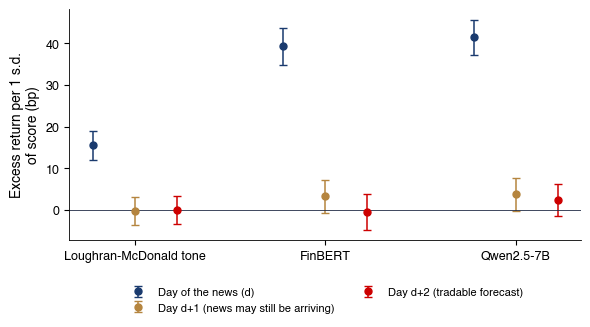

   saved ch15_contemp_next


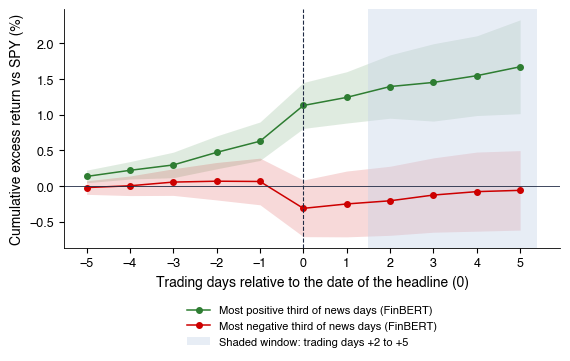

   saved ch15_event_study


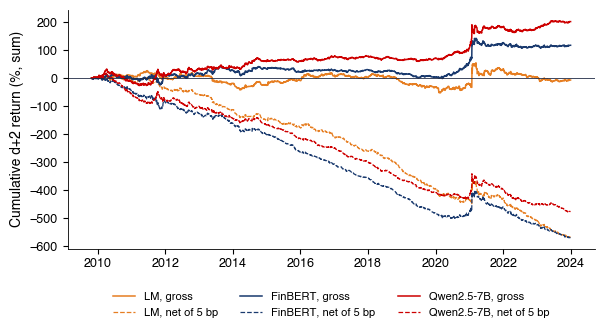

   saved ch15_strategy


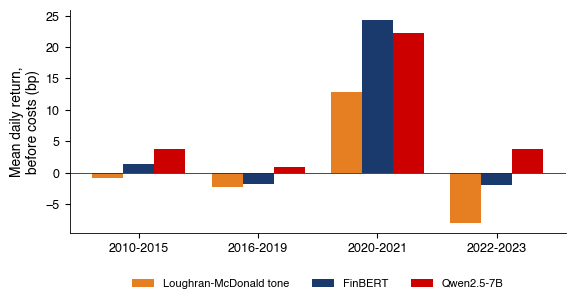

   saved ch15_subperiods
Regression b: percentage points of excess return per 1 SD of sentiment; the figure uses basis points
                 b       a  se_ols   se_cl    t_ols     t_cl      r2        n       G
lm|r0       0.1547  0.0889  0.0232  0.0181   6.6570   8.5343  0.0024  18282.0  3434.0
lm|r1      -0.0037  0.0620  0.0223  0.0171  -0.1635  -0.2135  0.0000  18282.0  3434.0
lm|r2      -0.0003  0.0707  0.0218  0.0174  -0.0118  -0.0148  0.0000  18282.0  3434.0
finbert|r0  0.3923  0.0889  0.0231  0.0227  16.9879  17.2712  0.0155  18282.0  3434.0
finbert|r1  0.0318  0.0620  0.0223  0.0199   1.4262   1.6002  0.0001  18282.0  3434.0
finbert|r2 -0.0054  0.0707  0.0218  0.0215  -0.2460  -0.2491  0.0000  18282.0  3434.0
qwen|r0     0.4145  0.0889  0.0231  0.0217  17.9649  19.0684  0.0173  18282.0  3434.0
qwen|r1     0.0369  0.0620  0.0223  0.0198   1.6547   1.8619  0.0001  18282.0  3434.0
qwen|r2     0.0232  0.0707  0.0218  0.0194   1.0621   1.1945  0.0001  18282.0  3434.0
Strategy means

In [7]:
P, rets = news_panel()
eval_news(P, rets)
fig_contemp_next()
fig_event_study()
fig_strategy()
fig_subperiods()
print('Regression b: percentage points of excess return per 1 SD of sentiment; the figure uses basis points')
print(pd.DataFrame(RES['news']['reg']).T.round(4).to_string())
print('Strategy means and intervals: basis points per day; Sharpe ratios annualised; net results deduct 5 bp per traded leg; break-even cost: bp per traded leg')
print(pd.DataFrame(RES['news']['strat']).T.reindex(columns=['mean_bp', 't', 'lo_bp', 'hi_bp', 'sr', 'mean_net_bp', 't_net', 'sr_net', 'breakeven_bp']).astype(float).to_string(float_format=lambda x: f'{x:.4g}'))
print('Gross subperiod mean returns (bp per day, before costs) and t-statistics')
print(pd.DataFrame({(score, period): row for score, stats_ in RES['news']['strat'].items() for period, row in stats_['years'].items()}).T.round(4))

![ch15_contemp_next](./ch15_contemp_next.png)

Output: `ch15_contemp_next.pdf`

![ch15_event_study](./ch15_event_study.png)

Output: `ch15_event_study.pdf`

![ch15_strategy](./ch15_strategy.png)

Output: `ch15_strategy.pdf`

![ch15_subperiods](./ch15_subperiods.png)

Output: `ch15_subperiods.pdf`